# Cristiano-free versus released encoder, paired comparison

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Reviewer 2.M1: the Cristiano et al. cohort is in both the pretraining corpus and the
Fig. 5 benchmark. A second encoder was pretrained without any Cristiano sample and the
cfDNA MIL benchmark re-run for it and for the released encoder: same outer and inner
splits, published hyperparameters, **10,000 fragments per sample** for both. Absolute
AUROCs are therefore lower than in Fig. 5 (100,000 fragments); the paired difference
is the quantity of interest.

AUROC is the Fig. 5 one: `prob_ensemble` pooled over the five outer test folds.
Paired bootstrap over samples, 5,000 resamples, seed 0 (the same resamples give the
per-arm CIs in panel b). Bold / `*`: the paired 95% CI of the difference excludes zero.

Plotting code is copied from `src/cfdna/fig5_no_cristiano_paired/make_paired.py`.

Panels:
- `cfdna_nocristiano_delta_forest` (a, ΔAUC per task)
- `cfdna_nocristiano_auc_bars` (b, AUROC per task for both encoders)


In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Data ──────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Helvetica'],
    'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 6,
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'lines.linewidth': 1, 'figure.dpi': 150, 'savefig.dpi': 600,
    'savefig.bbox': 'tight', 'axes.spines.top': False, 'axes.spines.right': False,
})

COL = {'pan_cancer': OKABE_ITO['black'], 'vs_healthy': OKABE_ITO['blue'], 'vs_other_cancers': OKABE_ITO['orange']}
LAB = {'pan_cancer': 'Pan-cancer', 'vs_healthy': 'vs Healthy', 'vs_other_cancers': 'vs Other cancers'}

T = pd.read_csv(DATA / "cfdna_nocristiano_paired_auc.csv", float_precision="round_trip")
assert len(T) == 15
order = (['cancer_vs_healthy'] + sorted(T.task[T.comparison == 'vs_healthy'])
         + sorted(T.task[T.comparison == 'vs_other_cancers']))
P = T.set_index('task').loc[order].reset_index()
print(P[['task', 'auc_released', 'auc_noCristiano', 'delta', 'ci_low', 'ci_high', 'ci_excludes_0']]
      .round(3).to_string(index=False))


                              task  auc_released  auc_noCristiano  delta  ci_low  ci_high  ci_excludes_0
                 cancer_vs_healthy         0.876            0.887  0.012  -0.008    0.031          False
       Bile_duct_cancer_vs_healthy         0.947            0.971  0.023  -0.010    0.068          False
          Breast_cancer_vs_healthy         0.871            0.886  0.015  -0.020    0.053          False
      Colorectal_cancer_vs_healthy         0.936            0.976  0.040   0.004    0.086           True
         Gastric_cancer_vs_healthy         0.968            0.954 -0.013  -0.045    0.004          False
            Lung_cancer_vs_healthy         0.868            0.897  0.029  -0.005    0.066          False
         Ovarian_cancer_vs_healthy         0.829            0.898  0.069  -0.016    0.156          False
      Pancreatic_cancer_vs_healthy         0.875            0.883  0.008  -0.037    0.055          False
 Bile_duct_cancer_vs_other_cancers         0.823       

saved: cfdna/output/cfdna_nocristiano_delta_forest.pdf
saved: cfdna/output/cfdna_nocristiano_delta_forest.png
saved: cfdna/output/cfdna_nocristiano_delta_forest.svg
saved: cfdna/output/cfdna_nocristiano_delta_forest.tsv


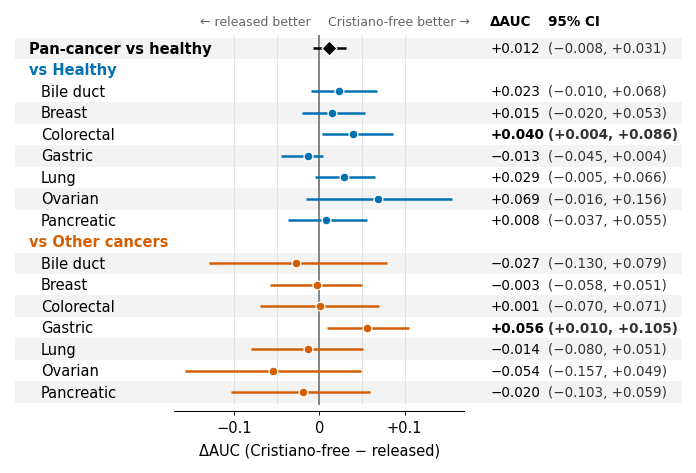

In [3]:
# ── Panel a: ΔAUC forest plot ─────────────────────────────────────────────────
# rows: pan-cancer, header, 7 vs healthy, header, 7 vs other (top to bottom); headers carry no data
yrow = np.concatenate([[0], np.arange(7) + 2, np.arange(7) + 10]); yhead = {'vs Healthy': 1, 'vs Other cancers': 9}
fig, ax = plt.subplots(figsize=(4.2, 3.2))
fig.subplots_adjust(left=0.24, right=0.70, top=0.90, bottom=0.13)
for k, y in enumerate(yrow):  # zebra stripes so each row can be followed to its value column
    if k % 2 == 0:
        ax.axhspan(y - 0.5, y + 0.5, xmin=-0.55, xmax=1.75, color='#F3F3F3', zorder=0, clip_on=False, lw=0)
for xv in [-0.1, -0.05, 0.05, 0.1]:
    ax.axvline(xv, color='#E2E2E2', linewidth=0.5, zorder=1)
ax.axvline(0, color='#666666', linewidth=0.75, zorder=1)
for comp in ['pan_cancer', 'vs_healthy', 'vs_other_cancers']:
    s = (P.comparison == comp).to_numpy()
    ax.hlines(yrow[s], P.ci_low[s], P.ci_high[s], color=COL[comp], linewidth=1.2, zorder=2)
    ax.scatter(P.delta[s], yrow[s], s=18 if comp != 'pan_cancer' else 26, marker='o' if comp != 'pan_cancer' else 'D',
               color=COL[comp], edgecolor='white', linewidth=0.6, zorder=3)
lim = 0.17
ax.set_xlim(-lim, lim); ax.set_ylim(yrow.max() + 0.6, -0.6)
ax.set_xticks([-0.1, 0, 0.1]); ax.set_xticklabels(['−0.1', '0', '+0.1'])
ax.set_yticks([])
ax.set_xlabel('ΔAUC (Cristiano-free − released)')
lab_tr = ax.get_yaxis_transform()  # x in axes fraction, y in data
for y, r in zip(yrow, P.itertuples()):
    is_pan = r.comparison == 'pan_cancer'
    ax.text(-0.50 if is_pan else -0.46, y, 'Pan-cancer vs healthy' if is_pan else r.cancer, transform=lab_tr,
            ha='left', va='center', fontsize=7, fontweight='bold' if is_pan else 'normal')
    ax.text(1.09, y, f'{r.delta:+.3f}'.replace('-', '−'), transform=lab_tr, ha='left', va='center', fontsize=6.5,
            fontweight='bold' if r.ci_excludes_0 else 'normal')
    ax.text(1.29, y, f'({r.ci_low:+.3f}, {r.ci_high:+.3f})'.replace('-', '−'), transform=lab_tr, ha='left', va='center', fontsize=6.5,
            color='#333333', fontweight='bold' if r.ci_excludes_0 else 'normal')
for txt, y in yhead.items():
    comp = 'vs_healthy' if txt == 'vs Healthy' else 'vs_other_cancers'
    ax.text(-0.50, y, txt, transform=lab_tr, ha='left', va='center', fontsize=7, fontweight='bold', color=COL[comp])
ax.text(1.09, 1.02, 'ΔAUC', transform=ax.transAxes, ha='left', va='bottom', fontsize=6.5, fontweight='bold')
ax.text(1.29, 1.02, '95% CI', transform=ax.transAxes, ha='left', va='bottom', fontsize=6.5, fontweight='bold')
ax.text(0.47, 1.02, '← released better', transform=ax.transAxes, ha='right', va='bottom', fontsize=6, color='#666666')
ax.text(0.53, 1.02, 'Cristiano-free better →', transform=ax.transAxes, ha='left', va='bottom', fontsize=6, color='#666666')
for side in ['left', 'right', 'top']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_position(('outward', 3)); ax.tick_params(axis='x', length=2, pad=2)
savefig(fig, OUT, 'cfdna_nocristiano_delta_forest',
        data=P[['task', 'cancer', 'comparison', 'auc_released', 'auc_noCristiano', 'delta', 'ci_low', 'ci_high', 'n', 'n_pos']])
plt.show()


saved: cfdna/output/cfdna_nocristiano_auc_bars.pdf
saved: cfdna/output/cfdna_nocristiano_auc_bars.png
saved: cfdna/output/cfdna_nocristiano_auc_bars.svg
saved: cfdna/output/cfdna_nocristiano_auc_bars.tsv


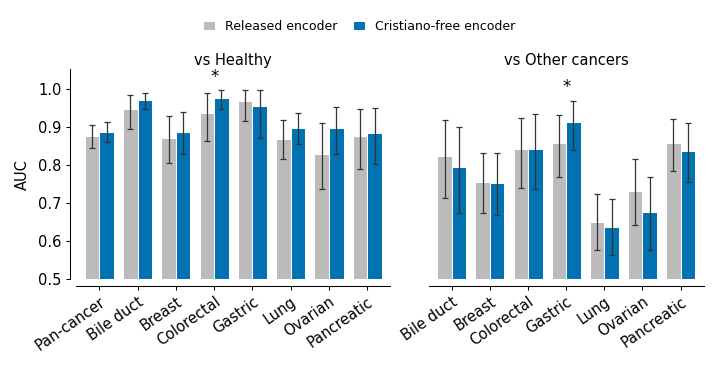

mean delta over 15 tasks +0.008; Cristiano-free higher in 9/15; CI excludes 0 in 2/15


In [4]:
# ── Panel b: AUROC per task, both encoders ────────────────────────────────────
ARM = [('released', 'Released encoder', '#BBBBBB'), ('noCristiano', 'Cristiano-free encoder', OKABE_ITO['blue'])]
CI = {'released': ('rel_ci_low', 'rel_ci_high'), 'noCristiano': ('nc_ci_low', 'nc_ci_high')}
groups = [('vs Healthy', P[P.comparison != 'vs_other_cancers']), ('vs Other cancers', P[P.comparison == 'vs_other_cancers'])]
fig, axes = plt.subplots(1, 2, figsize=(4.8, 2.4), sharey=True, gridspec_kw={'width_ratios': [len(g) for _, g in groups]})
width = 0.38
for ax, (title, G) in zip(axes, groups):
    x = np.arange(len(G))
    for k, (arm, lab, col) in enumerate(ARM):
        v = G[f'auc_{arm}'].to_numpy(); lo_, hi_ = (G[c].to_numpy() for c in CI[arm])
        ax.bar(x + (k - 0.5) * width, v - 0.5, width, bottom=0.5, yerr=[v - lo_, hi_ - v], capsize=1.5, color=col,
               edgecolor='white', linewidth=0.5, label=lab, error_kw={'linewidth': 0.6, 'capthick': 0.6, 'ecolor': '#333333'},
               zorder=2)
    for xi, r in zip(x, G.itertuples()):  # paired-bootstrap CI of the difference excludes 0
        if r.ci_excludes_0:
            ax.text(xi, max(r.rel_ci_high, r.nc_ci_high) + 0.012, '*', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(G.cancer)
    ax.set_title(title, fontsize=7, pad=2)
    ax.set_xlim(-0.6, len(G) - 0.4)
    ax.spines['bottom'].set_position(('outward', 3)); ax.tick_params(axis='both', which='both', length=2, pad=2)
    plt.setp(ax.get_xticklabels(), rotation=35, ha='right', rotation_mode='anchor')  # after tick_params, which resets it
axes[0].set_ylim(0.5, 1.05); axes[0].set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0]); axes[0].set_ylabel('AUC')
axes[0].spines['left'].set_position(('outward', 3))
axes[1].spines['left'].set_visible(False); axes[1].tick_params(axis='y', length=0)
plt.tight_layout(w_pad=0.4, rect=(0, 0, 1, 0.92))
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False,
           fontsize=6, handlelength=1.0, columnspacing=1.2)
savefig(fig, OUT, 'cfdna_nocristiano_auc_bars',
        data=P[['task', 'cancer', 'comparison', 'auc_released', 'rel_ci_low', 'rel_ci_high', 'auc_noCristiano',
                'nc_ci_low', 'nc_ci_high', 'delta', 'ci_low', 'ci_high', 'ci_excludes_0']])
plt.show()
d = P.delta.to_numpy()
print(f"mean delta over 15 tasks {d.mean():+.3f}; Cristiano-free higher in {(d > 0).sum()}/15; "
      f"CI excludes 0 in {P.ci_excludes_0.sum()}/15")
